# Taller de Recuperación · Grupo Senior · Programa Horizontes 2026
## Acceso a tecnología y puntaje en Saber 11: un modelo de regresión (ODS 4)

### Paso 1 · Pregunta de negocio
- **Estudiante:** Juan Diego Bedoya Gutiérrez
- **Pregunta de negocio:** ¿Cuál es el puntaje global esperado de un estudiante en Saber 11 según su acceso a internet y computador en el hogar, a igualdad de nivel socioeconómico (estrato y educación de los padres)?
- **Quién usaría el resultado:** Secretarías de Educación, Ministerio de Educación y programas de conectividad como el de MinTIC.
- **Decisión que apoya:** priorizar los subsidios de conectividad y equipos en los perfiles de estudiantes con menor puntaje esperado, es decir, en los colegios donde más se concentran esos perfiles.
- **Tipo de problema:** Regresión (predecir un número).
- **Variable objetivo:** `punt_global` (puntaje total de Saber 11, de 0 a 500).
- **Fuente de datos:** [Resultados únicos Saber 11 (ICFES) en datos.gov.co](https://www.datos.gov.co/Educaci-n/Vista-Resultados-nicos-Saber-11/d5t8-3yqf)
- **ODS:** 4 · Educación de calidad.

**Librerías.** Cargamos las herramientas para manejar datos, hacer gráficos y construir modelos.

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

### Paso 2 · Carga y descripción de los datos
El dataset completo tiene millones de filas, así que traemos una muestra de 36.613 desde la API oficial de datos.gov.co (el taller recomienda entre 1.000 y 100.000 filas).

In [23]:
url = "https://www.datos.gov.co/resource/d5t8-3yqf.csv?$limit=50000"
df = pd.read_csv(url)

# Nos quedamos solo con las columnas que necesitamos
columnas = ["punt_global", "fami_tieneinternet", "fami_tienecomputador",
            "fami_estratovivienda", "fami_educacionpadre", "fami_educacionmadre",
            "cole_area_ubicacion", "cole_naturaleza"]

faltan = [c for c in columnas if c not in df.columns]
print("Columnas que faltan (debe salir vacío):", faltan)

df = df[columnas]
print("Filas y columnas:", df.shape)
df.head()

Columnas que faltan (debe salir vacío): []
Filas y columnas: (36613, 8)


,punt_global,fami_tieneinternet,fami_tienecomputador,fami_estratovivienda,fami_educacionpadre,fami_educacionmadre,cole_area_ubicacion,cole_naturaleza
0,NaN,No,Si,Estrato 2,Primaria completa,Primaria completa,URBANO,OFICIAL
1,287.0,Si,Si,Estrato 2,Secundaria (Bachillerato) completa,Secundaria (Bachillerato) completa,URBANO,OFICIAL
2,292.0,Si,Si,Estrato 1,Secundaria (Bachillerato) incompleta,Primaria incompleta,URBANO,OFICIAL
3,300.0,No,No,Estrato 2,Secundaria (Bachillerato) incompleta,Secundaria (Bachillerato) completa,URBANO,OFICIAL
4,185.0,Si,Si,Estrato 2,Técnica o tecnológica completa,Técnica o tecnológica incompleta,URBANO,NO OFICIAL


In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36613 entries, 0 to 36612
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   punt_global           23474 non-null  float64
 1   fami_tieneinternet    35722 non-null  object 
 2   fami_tienecomputador  35646 non-null  object 
 3   fami_estratovivienda  35593 non-null  object 
 4   fami_educacionpadre   35260 non-null  object 
 5   fami_educacionmadre   35252 non-null  object 
 6   cole_area_ubicacion   36583 non-null  object 
 7   cole_naturaleza       36613 non-null  object 
dtypes: float64(1), object(7)
memory usage: 2.2+ MB


In [25]:
df.describe()

,punt_global
count,23474.000000
mean,269.953310
std,44.488623
min,0.000000
25%,238.000000
50%,269.000000
75%,301.000000
max,449.000000


**Significado de las variables**
- `punt_global`: puntaje total del estudiante (0 a 500). Es lo que queremos predecir.
- `fami_tieneinternet`: si el hogar tiene internet (Si / No).
- `fami_tienecomputador`: si el hogar tiene computador (Si / No).
- `fami_estratovivienda`: estrato de la vivienda. Es un indicador del nivel económico del hogar.
- `fami_educacionpadre` y `fami_educacionmadre`: nivel de estudios del padre y de la madre. Junto con el estrato, forman el nivel socioeconómico que usamos como control.
- `cole_area_ubicacion`: zona del colegio (urbano / rural).
- `cole_naturaleza`: colegio oficial o no oficial.

**Lo que se observa en los datos:** la muestra tiene 36.613 filas y 8 columnas. El puntaje global solo está disponible para 23.474 estudiantes (el 36 % restante no tiene puntaje), con un promedio de 270 puntos, una desviación estándar de 44 y valores entre 0 y 449. Las demás variables son categorías (Sí/No, estrato, nivel educativo, zona y tipo de colegio) y tienen pocos datos faltantes, menos del 4 %. Estos nulos se revisan en el Paso 3 y se limpian en el Paso 4.

### Paso 3 · Análisis exploratorio (EDA)
Primero revisamos nulos, duplicados y atípicos. Después hacemos los gráficos, cada uno con su interpretación.

In [26]:
# Nulos
print("Nulos por columna:")
print(df.isnull().sum())

# Duplicados
print("\nFilas duplicadas:", df.duplicated().sum())

# Atípicos del puntaje con el método IQR
q1 = df["punt_global"].quantile(0.25)
q3 = df["punt_global"].quantile(0.75)
iqr = q3 - q1
limite_bajo = q1 - 1.5 * iqr
limite_alto = q3 + 1.5 * iqr
atipicos = df[(df["punt_global"] < limite_bajo) | (df["punt_global"] > limite_alto)]
print(f"\nAtípicos según IQR (fuera de {limite_bajo:.0f} - {limite_alto:.0f}):", len(atipicos))

Nulos por columna:
punt_global             13139
fami_tieneinternet        891
fami_tienecomputador      967
fami_estratovivienda     1020
fami_educacionpadre      1353
fami_educacionmadre      1361
cole_area_ubicacion        30
cole_naturaleza             0
dtype: int64

Filas duplicadas: 20740

Atípicos según IQR (fuera de 144 - 396): 65


In [27]:
# Porcentaje de nulos por columna
print((df.isnull().mean() * 100).round(1))

# Duplicados solo entre filas completas (ya sin nulos)
df_completo = df.dropna()
print("Duplicados:", df_completo.duplicated().sum(), "de", len(df_completo), "filas")

punt_global             35.9
fami_tieneinternet       2.4
fami_tienecomputador     2.6
fami_estratovivienda     2.8
fami_educacionpadre      3.7
fami_educacionmadre      3.7
cole_area_ubicacion      0.1
cole_naturaleza          0.0
dtype: float64
Duplicados: 8622 de 22408 filas


In [28]:
print("Atípicos bajos:", (df["punt_global"] < limite_bajo).sum())
print("Atípicos altos:", (df["punt_global"] > limite_alto).sum())
print("Puntajes en 0:", (df["punt_global"] == 0).sum())

Atípicos bajos: 8
Atípicos altos: 57
Puntajes en 0: 1


In [29]:
print("Promedio con duplicados:", df_completo["punt_global"].mean().round(1))
print("Promedio sin duplicados:", df_completo.drop_duplicates()["punt_global"].mean().round(1))

Promedio con duplicados: 270.4
Promedio sin duplicados: 271.4


**Lectura de la revisión:**

- **Nulos:** el dataset tiene 36.613 filas y 13.139 de ellas (35,9 %) no tienen puntaje global, así que no sirven para entrenar el modelo y se eliminan. En las demás columnas falta menos del 4 % de los datos (internet 2,4 %, computador 2,6 %, estrato 2,8 %, educación de los padres 3,7 %, zona del colegio 0,1 %), por lo que quitar esas filas casi no afecta el análisis. Después de la limpieza quedan 22.408 estudiantes.
- **Duplicados:** entre las filas completas hay 8.622 repetidas (38 %). No las eliminamos, porque el dataset no tiene un identificador del estudiante y las variables son categorías (Sí/No, estrato, nivel educativo), por lo que es normal que distintos estudiantes tengan exactamente el mismo perfil. Para comprobarlo comparé el puntaje promedio con y sin duplicados: 270,4 frente a 271,4. La diferencia es de solo 1 punto sobre 500, así que no distorsionan el resultado.
- **Atípicos:** según el método IQR, los puntajes normales van de 144 a 396. Solo 65 estudiantes (0,3 %) quedan fuera de ese rango: 8 por debajo y 57 por encima. La mayoría son estudiantes con puntajes sobresalientes, que son resultados reales y no errores. Hay un solo puntaje en 0. Los conservamos porque son pocos y no cambian el modelo.



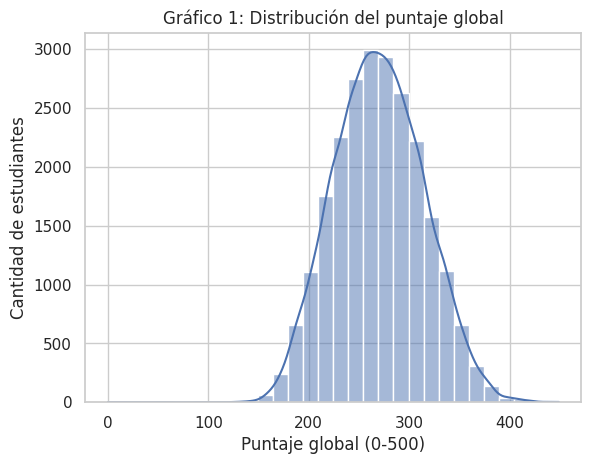

In [30]:
# Gráfico 1: distribución del puntaje global
sns.histplot(df["punt_global"].dropna(), bins=30, kde=True)
plt.title("Gráfico 1: Distribución del puntaje global")
plt.xlabel("Puntaje global (0-500)")
plt.ylabel("Cantidad de estudiantes")
plt.show()

**Interpretación del Gráfico 1:** La distribución del puntaje global tiene forma de campana y es bastante simétrica. El puntaje promedio es de 270 puntos y la mediana de 269, casi iguales, lo que indica que no hay un grupo de puntajes que distorsione el resultado. La mitad de los estudiantes obtuvo entre 238 y 301 puntos, y muy pocos quedan por debajo de 150 o por encima de 400. Esta forma es favorable para el modelo de regresión, porque el puntaje se comporta de manera regular y no tiene sesgos extremos.

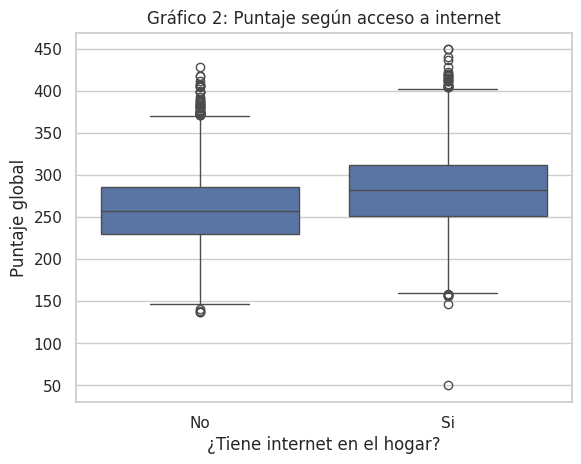

fami_tieneinternet
No    258.4
Si    281.3
Name: punt_global, dtype: float64


In [31]:
# Gráfico 2: puntaje según acceso a internet
sns.boxplot(data=df, x="fami_tieneinternet", y="punt_global")
plt.title("Gráfico 2: Puntaje según acceso a internet")
plt.xlabel("¿Tiene internet en el hogar?")
plt.ylabel("Puntaje global")
plt.show()

print(df.groupby("fami_tieneinternet")["punt_global"].mean().round(1))

**Interpretación del Gráfico 2:** Los estudiantes que tienen internet en el hogar obtienen un puntaje promedio de 281,3, frente a 258,4 de quienes no lo tienen, es decir, unos 23 puntos más. La caja de quienes tienen internet está desplazada hacia arriba, lo que indica que la mayoría de ese grupo obtiene puntajes más altos. Sin embargo, las cajas se traslapan: hay estudiantes sin internet con buenos resultados y estudiantes con internet con resultados bajos, por lo que el internet por sí solo no determina el puntaje. Además, esta comparación no considera el nivel socioeconómico, así que parte de la diferencia puede deberse a que los hogares con internet tienen, en promedio, mejores condiciones económicas. Por eso más adelante el modelo incluye el estrato y la educación de los padres.

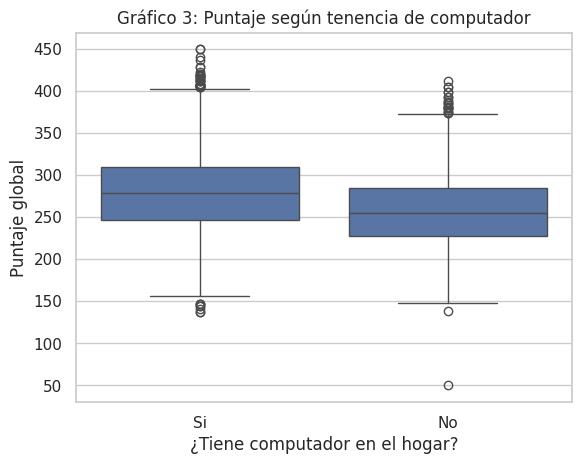

fami_tienecomputador
No    256.7
Si    278.3
Name: punt_global, dtype: float64


In [32]:
# Gráfico 3: puntaje según tenencia de computador
sns.boxplot(data=df, x="fami_tienecomputador", y="punt_global")
plt.title("Gráfico 3: Puntaje según tenencia de computador")
plt.xlabel("¿Tiene computador en el hogar?")
plt.ylabel("Puntaje global")
plt.show()

print(df.groupby("fami_tienecomputador")["punt_global"].mean().round(1))

**Interpretación del Gráfico 3:** Los estudiantes que tienen computador en el hogar obtienen un puntaje promedio de 278,3, frente a 256,7 de quienes no lo tienen, es decir, unos 22 puntos más. El resultado es muy parecido al del internet (23 puntos de diferencia), lo que sugiere que ambos recursos se asocian de forma similar con el puntaje. Igual que antes, las cajas se traslapan, así que tener computador no determina por sí solo el resultado. Además, es probable que muchos hogares con computador también tengan internet y mejores condiciones económicas, por lo que parte de esta diferencia puede no deberse solo al computador. El modelo de regresión nos ayudará a separar el efecto de cada variable.

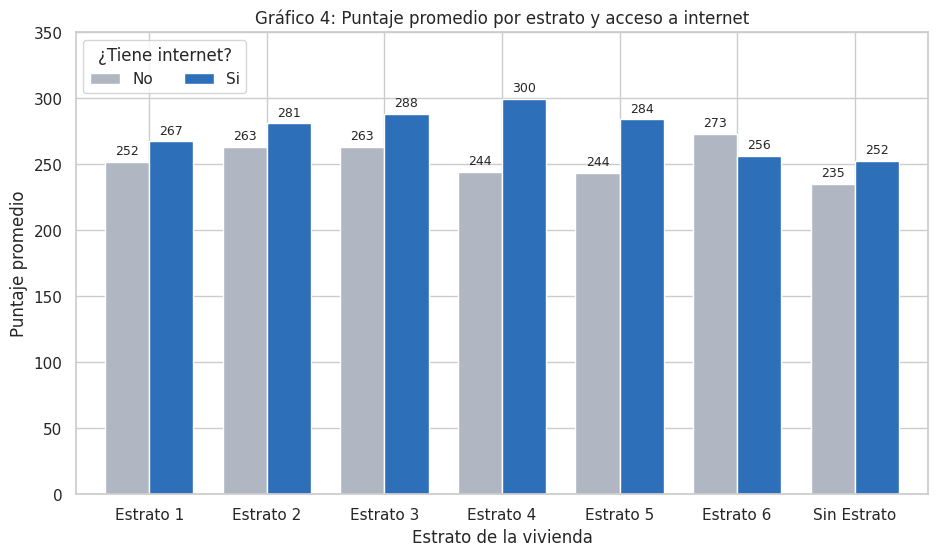

Diferencia (Si - No) por estrato:
fami_estratovivienda
Estrato 1      15.7
Estrato 2      17.6
Estrato 3      25.0
Estrato 4      55.2
Estrato 5      40.4
Estrato 6     -17.0
Sin Estrato    17.4
dtype: float64


In [33]:
# Gráfico 4: ¿la brecha de internet se mantiene dentro de cada estrato?
tabla = df.groupby(["fami_estratovivienda", "fami_tieneinternet"])["punt_global"].mean().unstack()

ax = tabla.plot(kind="bar", figsize=(11, 6), color=["#B0B7C3", "#2E6FBA"], width=0.75)

# Números encima de cada barra
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.0f", padding=3, fontsize=9)

ax.set_title("Gráfico 4: Puntaje promedio por estrato y acceso a internet")
ax.set_xlabel("Estrato de la vivienda")
ax.set_ylabel("Puntaje promedio")
ax.set_ylim(0, 350)
ax.legend(title="¿Tiene internet?", loc="upper left", ncol=2)
plt.xticks(rotation=0)
plt.show()

# Diferencia en puntos entre quienes tienen y no tienen internet, por estrato
print("Diferencia (Si - No) por estrato:")
print((tabla["Si"] - tabla["No"]).round(1))

In [34]:
print(df.groupby(["fami_estratovivienda", "fami_tieneinternet"]).size().unstack())

fami_tieneinternet       No     Si
fami_estratovivienda              
Estrato 1              7321   1621
Estrato 2             11408  10046
Estrato 3               898   3241
Estrato 4                59    579
Estrato 5                29     87
Estrato 6                 8     20
Sin Estrato              88     53


**Interpretación del Gráfico 4:** Dentro de los estratos con más estudiantes (1, 2 y 3, que reúnen cerca del 96 % de los datos), quienes tienen internet obtienen un puntaje promedio mayor: 16, 18 y 25 puntos más, respectivamente. Esta diferencia es algo menor que los 23 puntos de la comparación general (Gráfico 2) en los estratos 1 y 2, lo que indica que una parte de la brecha se debe al nivel socioeconómico y no solo al internet. Aun así, la diferencia se mantiene dentro de cada estrato. En los estratos 4, 5 y 6 y en "Sin estrato" hay muy pocos estudiantes sin internet (entre 8 y 88), por lo que sus promedios no son confiables y no se interpretan; por ejemplo, el resultado negativo del estrato 6 se basa en solo 8 estudiantes. También se observa que la falta de internet se concentra en los estratos bajos: el 82 % de los estudiantes de estrato 1 no tiene internet, frente al 9 % en el estrato 4. Estos resultados refuerzan la necesidad de incluir el estrato en el modelo.

Categorías que no coinciden con la lista: []


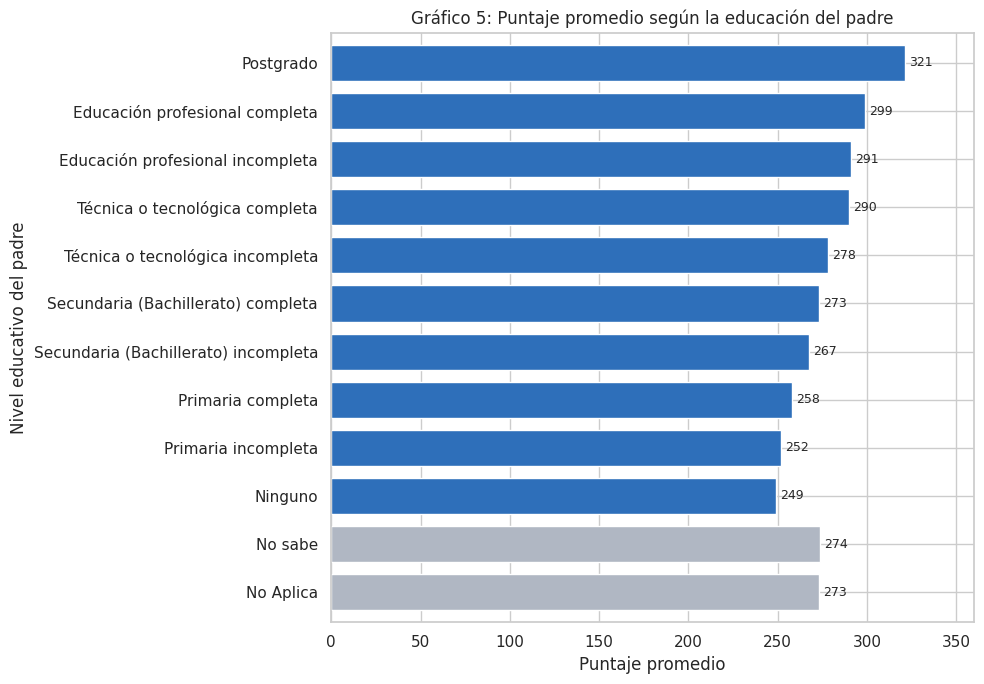

Diferencia entre Postgrado y Ninguno: 72.1 puntos

Estudiantes por nivel:
fami_educacionpadre
Secundaria (Bachillerato) completa      6972
Primaria incompleta                     6923
Primaria completa                       6532
Secundaria (Bachillerato) incompleta    5061
Educación profesional completa          3055
Técnica o tecnológica completa          2260
No sabe                                 1525
Ninguno                                  853
Postgrado                                738
Educación profesional incompleta         602
Técnica o tecnológica incompleta         549
No Aplica                                190
Name: count, dtype: int64


In [35]:
# Gráfico 5: puntaje promedio según la educación del padre

# Orden lógico, de menor a mayor nivel (las categorías sin información van abajo)
orden = ["No Aplica", "No sabe", "Ninguno", "Primaria incompleta", "Primaria completa",
         "Secundaria (Bachillerato) incompleta", "Secundaria (Bachillerato) completa",
         "Técnica o tecnológica incompleta", "Técnica o tecnológica completa",
         "Educación profesional incompleta", "Educación profesional completa", "Postgrado"]

promedios = df.groupby("fami_educacionpadre")["punt_global"].mean()
print("Categorías que no coinciden con la lista:", [c for c in promedios.index if c not in orden])
promedios = promedios.reindex([c for c in orden if c in promedios.index])

# Gris para las categorías sin información, azul para los niveles educativos
colores = ["#B0B7C3" if c in ["No Aplica", "No sabe"] else "#2E6FBA" for c in promedios.index]

ax = promedios.plot(kind="barh", figsize=(10, 7), color=colores, width=0.75)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3, fontsize=9)

ax.set_title("Gráfico 5: Puntaje promedio según la educación del padre")
ax.set_xlabel("Puntaje promedio")
ax.set_ylabel("Nivel educativo del padre")
ax.set_xlim(0, 360)
plt.tight_layout()
plt.show()

print("Diferencia entre Postgrado y Ninguno:", round(promedios["Postgrado"] - promedios["Ninguno"], 1), "puntos")
print()
print("Estudiantes por nivel:")
print(df["fami_educacionpadre"].value_counts())

**Interpretación del Gráfico 5:** El puntaje promedio aumenta de forma constante con el nivel educativo del padre: pasa de 249 puntos cuando no tiene estudios a 321 cuando tiene postgrado, una diferencia de 72 puntos, mucho mayor que la asociada al internet (23 puntos) o al computador (22 puntos). Todos los niveles tienen cientos o miles de estudiantes, por lo que los promedios son confiables. Las categorías "No sabe" y "No Aplica" (en gris) no corresponden a un nivel educativo, por lo que no se interpretan. Este resultado indica que el entorno del hogar influye mucho en el puntaje y confirma que conviene controlarlo en el modelo: así el efecto del internet y del computador se estima entre estudiantes con padres del mismo nivel educativo. La educación de la madre se espera similar, aunque no se graficó.

### Paso 4 · Preparación de datos

- **Nulos:** eliminamos las filas que tengan algún dato faltante en las columnas que usamos. Si son pocas, no afecta el resultado y mantiene el modelo simple.
- **Duplicados y atípicos:** los conservamos. Los duplicados son estudiantes distintos con respuestas iguales, y los puntajes extremos son resultados reales.
- **Categorías a números:** el modelo solo entiende números, así que convertimos cada categoría en columnas de 0 y 1 (`get_dummies`).
- **Entrenamiento y prueba:** 80 % para que el modelo aprenda y 20 % para evaluarlo con datos que no ha visto.

In [36]:
filas_antes = len(df)
df_modelo = df.dropna().copy()
print(f"Filas antes: {filas_antes} | después de quitar nulos: {len(df_modelo)}")

X = pd.get_dummies(df_modelo.drop(columns="punt_global"), drop_first=True, dtype=int)
y = df_modelo["punt_global"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Filas antes: 36613 | después de quitar nulos: 22408
Entrenamiento: (17926, 32) | Prueba: (4482, 32)


En el Paso 3 solo revisamos los datos. Aquí aplicamos esas decisiones: quitamos las filas con datos faltantes (de 36.613 quedan 22.408), convertimos las categorías a números y separamos los datos en entrenamiento y prueba.

### Paso 5 · Modelado
Entrenamos tres modelos:
1. **Regresión lineal (con tecnología):** sencilla y fácil de explicar. Sus coeficientes dicen cuántos puntos suma o resta cada variable, manteniendo las demás iguales.
2. **Random Forest (con tecnología):** más flexible, sirve para comparar si hay relaciones que la lineal no captura.
3. **Regresión lineal base (sin internet ni computador):** sirve de control. Si el modelo con tecnología predice mejor que este, la tecnología aporta información.

In [37]:
# Modelo 1: regresión lineal con todas las variables
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train, y_train)
pred_lineal = modelo_lineal.predict(X_test)

# Modelo 2: Random Forest con todas las variables
modelo_rf = RandomForestRegressor(n_estimators=50, max_depth=8, random_state=42, n_jobs=-1)
modelo_rf.fit(X_train, y_train)
pred_rf = modelo_rf.predict(X_test)

# Modelo 3 (control): regresión lineal SIN internet ni computador
columnas_sin_tec = [c for c in X.columns if "internet" not in c and "computador" not in c]
modelo_base = LinearRegression()
modelo_base.fit(X_train[columnas_sin_tec], y_train)
pred_base = modelo_base.predict(X_test[columnas_sin_tec])

print("Modelos entrenados.")

Modelos entrenados.


### Paso 6 · Evaluación
Para regresión usamos tres métricas:
- **MAE:** error promedio, en puntos.
- **RMSE:** parecido al MAE, pero castiga más los errores grandes.
- **R²:** qué porcentaje de las diferencias de puntaje explica el modelo (0 = nada, 1 = todo).

In [38]:
def evaluar(nombre, y_real, y_pred):
    return {
        "Modelo": nombre,
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "R2": r2_score(y_real, y_pred),
    }

resultados = pd.DataFrame([
    evaluar("Lineal con tecnología", y_test, pred_lineal),
    evaluar("Random Forest con tecnología", y_test, pred_rf),
    evaluar("Lineal sin tecnología (base)", y_test, pred_base),
]).round(3)
resultados

,Modelo,MAE,RMSE,R2
0,Lineal con tecnología,32.148,39.878,0.183
1,Random Forest con tecnología,32.067,39.802,0.186
2,Lineal sin tecnología (base),32.327,40.046,0.176


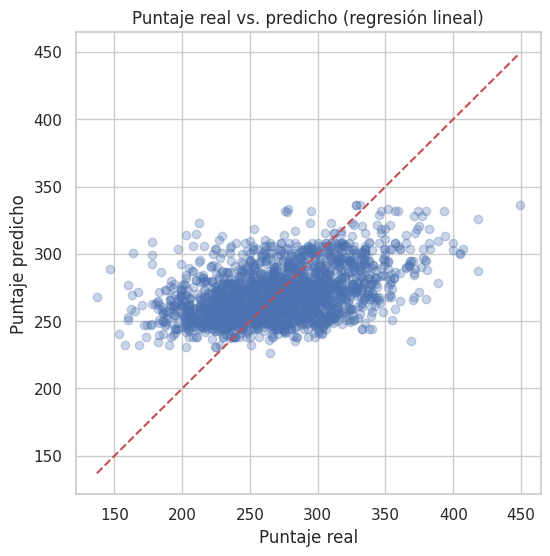

In [39]:
# Gráfico real vs. predicho (mostramos una muestra para que se vea claro)
muestra = np.random.RandomState(42).choice(len(y_test), size=min(2000, len(y_test)), replace=False)

plt.figure(figsize=(6, 6))
plt.scatter(y_test.iloc[muestra], pred_lineal[muestra], alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.title("Puntaje real vs. predicho (regresión lineal)")
plt.xlabel("Puntaje real")
plt.ylabel("Puntaje predicho")
plt.show()

- **Gráfico real vs. predicho:** si el modelo fuera perfecto, todos los puntos estarían sobre la línea roja. Aquí forman una nube achatada: las predicciones se concentran entre 230 y 320 puntos, mientras que los puntajes reales van de 150 a 450. El modelo tiende a predecir valores cercanos al promedio, subestima a los estudiantes con puntajes altos y sobrestima a los de puntajes bajos.

In [40]:
# ¿Cuántos puntos suma o resta cada variable? (coeficientes de la regresión lineal)
coeficientes = pd.Series(modelo_lineal.coef_, index=X.columns).sort_values()
print(coeficientes.round(1))

print("\n--- Variables de tecnología ---")
print(coeficientes[coeficientes.index.str.contains("internet|computador")].round(1))

fami_educacionmadre_Ninguno                                -32.1
fami_educacionpadre_Ninguno                                -25.1
fami_educacionmadre_Primaria incompleta                    -24.3
fami_educacionmadre_Primaria completa                      -22.9
fami_educacionpadre_Primaria incompleta                    -21.3
fami_estratovivienda_Sin Estrato                           -20.1
fami_educacionpadre_Primaria completa                      -18.8
fami_educacionmadre_Secundaria (Bachillerato) incompleta   -18.7
fami_educacionpadre_Secundaria (Bachillerato) incompleta   -16.2
fami_educacionmadre_No sabe                                -15.1
fami_educacionpadre_Secundaria (Bachillerato) completa     -14.4
fami_educacionpadre_Técnica o tecnológica incompleta       -14.0
fami_educacionmadre_Secundaria (Bachillerato) completa     -13.8
fami_educacionpadre_No sabe                                -12.6
fami_educacionmadre_No Aplica                              -10.7
fami_estratovivienda_Estr

**Cómo leer los coeficientes:** cada número indica cuántos puntos suma (signo positivo) o resta (signo negativo) esa característica frente a una categoría de referencia, manteniendo las demás variables iguales. Las categorías de referencia no aparecen en la lista: son el estrato 1, la educación profesional completa (del padre y de la madre), la zona rural y el colegio no oficial. Por eso la mayoría de los niveles de educación salen en negativo: están por debajo de la educación profesional completa. Los coeficientes de los estratos 5 y 6 no se interpretan porque tienen muy pocos estudiantes.

**Puntaje esperado por perfil.** Con el modelo lineal calculamos el puntaje esperado promedio de cada perfil de estudiante (según internet, computador y educación del padre). Solo mostramos perfiles con al menos 30 estudiantes, para que el promedio sea confiable. Los de arriba son los de menor puntaje esperado.

In [41]:
perfiles = df_modelo[["fami_tieneinternet", "fami_tienecomputador", "fami_educacionpadre"]].copy()
perfiles["puntaje_esperado"] = modelo_lineal.predict(X)

tabla_perfiles = perfiles.groupby(
    ["fami_tieneinternet", "fami_tienecomputador", "fami_educacionpadre"]
).agg(estudiantes=("puntaje_esperado", "size"),
      puntaje_esperado=("puntaje_esperado", "mean"))

tabla_perfiles = tabla_perfiles[tabla_perfiles["estudiantes"] >= 30].sort_values("puntaje_esperado")
tabla_perfiles.head(10).round(1)

estudiantes  \
fami_tieneinternet fami_tienecomputador fami_educacionpadre                                 
No                 No                   Ninguno                                       255   
                                        Primaria incompleta                          2152   
Si                 No                   Ninguno                                        40   
No                 No                   Primaria completa                            1584   
                   Si                   Ninguno                                        95   
                                        Primaria incompleta                           882   
Si                 No                   Primaria incompleta                           316   
No                 No                   Secundaria (Bachillerato) incompleta          878   
Si                 No                   Primaria completa                             209   
No                 Si                   Primaria completa                             930   

                                                                              puntaje_esperado  
fami_tieneinternet fami_tienecomputador fami_educacionpadre                                     
No                 No                   Ninguno                                          240.5  
                                        Primaria incompleta                              246.4  
Si                 No                   Ninguno                                          246.4  
No                 No                   Primaria completa                                250.8  
                   Si                   Ninguno                                          252.8  
                                        Primaria incompleta                              254.5  
Si                 No                   Primaria incompleta                              255.7  
No                 No                   Secundaria (Bachillerato) incompleta             257.8  
Si                 No                   Primaria completa                                259.2  
No                 Si                   Primaria completa                                259.5

In [42]:
tabla_perfiles.tail(5).round(1)

estudiantes  \
fami_tieneinternet fami_tienecomputador fami_educacionpadre                             
No                 Si                   Educación profesional completa            227   
Si                 Si                   Técnica o tecnológica completa           1146   
                                        Educación profesional incompleta          302   
                                        Educación profesional completa           1611   
                                        Postgrado                                 428   

                                                                          puntaje_esperado  
fami_tieneinternet fami_tienecomputador fami_educacionpadre                                 
No                 Si                   Educación profesional completa               292.8  
Si                 Si                   Técnica o tecnológica completa               294.2  
                                        Educación profesional incompleta             294.6  
                                        Educación profesional completa               301.8  
                                        Postgrado                                    322.2


**Qué significan los resultados para el negocio**
- **MAE:** el modelo se equivoca, en promedio, en unos 32 puntos sobre 500. Como los puntajes de los estudiantes se desvían de forma natural unos 44 puntos del promedio, el modelo mejora un poco, pero no es muy preciso.
- **R²:** las variables del modelo explican cerca del 18 % de las diferencias de puntaje. El resto depende de factores que no están en los datos, como el colegio, la motivación o la calidad de la enseñanza. Por eso el modelo sirve para entender tendencias, no para predecir el puntaje de un estudiante en particular.
- **Con vs. sin tecnología:** al agregar internet y computador, el R² sube de 0,176 a 0,183 y el error baja solo 0,2 puntos. Es decir, una vez se conocen el estrato y la educación de los padres, la tecnología aporta poca información adicional. Esto sugiere que gran parte de la diferencia que vimos en el análisis exploratorio está ligada al nivel socioeconómico de los hogares.
-  **Coeficientes:** a igualdad de estrato, educación de los padres, zona y tipo de colegio, tener internet se asocia a 5,2 puntos más y tener computador a 6,4 puntos más (unos 11,6 puntos si el hogar tiene ambos). Es una diferencia mucho menor que la observada sin controlar (23 y 22 puntos), lo que indica que la mayor parte de la brecha inicial se explica por el nivel socioeconómico del hogar. Las variables que más pesan son la educación de los padres: por ejemplo, una madre sin estudios se asocia a 32 puntos menos que una con educación profesional completa, y una con postgrado a 15 puntos más. El estrato pesa poco una vez se incluye la educación de los padres. Los coeficientes de los estratos 5 y 6 no se interpretan porque tienen muy pocos estudiantes. Cada coeficiente se compara con una categoría base (estrato 1, educación profesional completa, zona rural y colegio no oficial).

- **Perfiles:** el perfil con menor puntaje esperado es el de estudiantes sin internet, sin computador y con padre sin estudios: 240,5 puntos. El de mayor puntaje es el de estudiantes con internet, computador y padre con postgrado: 322,2 puntos, unos 82 puntos más. De esa distancia, la tecnología explica unos 12 puntos (5,2 de internet y 6,4 de computador); el resto está ligado sobre todo a la educación de los padres. Los perfiles más numerosos entre los de menor puntaje son los que no tienen internet ni computador y cuyo padre tiene primaria incompleta (2.152 estudiantes, 246,4 puntos) o primaria completa (1.584 estudiantes, 250,8 puntos). En cambio, todos los perfiles de mayor puntaje tienen computador y padres con educación técnica, profesional o postgrado. Los perfiles de 40 y 95 estudiantes se interpretan con cautela por su tamaño.

**Modelo elegido:** la regresión lineal. El Random Forest tiene un resultado casi igual (R² de 0,186 frente a 0,183) pero es más difícil de explicar, así que preferimos el modelo más sencillo.

### Paso 7 · Conclusiones y limitaciones

**Respuesta a la pregunta de negocio**

El puntaje global esperado de un estudiante en Saber 11 va desde unos 240 puntos, cuando no tiene internet ni computador y su padre no tiene estudios, hasta unos 322 puntos, cuando tiene ambos recursos y su padre tiene postgrado; el promedio general es de 270. A igualdad de estrato, educación de los padres, zona y tipo de colegio, tener internet se asocia a 5,2 puntos más y tener computador a 6,4 puntos más. Es una ventaja real pero pequeña, mucho menor que la que se asocia a la educación de los padres, y gran parte de la brecha que se ve a simple vista (unos 23 puntos) está ligada al nivel socioeconómico del hogar. Como el modelo explica cerca del 18 % de las diferencias de puntaje, estos valores sirven para entender tendencias y no para predecir el resultado de un estudiante en particular.

**Acciones concretas**
1. Priorizar los subsidios de conectividad y equipos en los perfiles grandes de menor puntaje esperado: estudiantes sin internet ni computador cuyo padre tiene primaria incompleta o completa (cerca de 3.700 estudiantes, 17 % de la muestra), y, por extensión, en los colegios donde más se concentran.
2. No limitar la ayuda a la entrega de equipos: acompañarla con formación para su uso académico y con apoyo escolar dirigido a hogares con menor nivel educativo, porque la tecnología sola se asocia a una mejora pequeña (unos 11 puntos si el hogar tiene ambos recursos).

**Limitaciones**
- **Asociación no es causalidad:** el modelo muestra que tener internet o computador se asocia a mayor puntaje, pero no prueba que la tecnología sea la causa. Hay factores que no están en los datos y que se relacionan con ambos.
- **Control imperfecto:** incluir el estrato y la educación de los padres reduce el problema, pero no lo elimina.
- **Variables no incluidas:** no hay datos sobre la calidad de la conexión, el uso real del computador ni la calidad del colegio.
- **Categorías poco claras:** la educación de los padres incluye opciones como "No sabe", que mezclan casos distintos.
- **Nivel de análisis:** el modelo predice por estudiante. Hablar de colegios es una extensión: no se calculó el puntaje por colegio.
- **Muestra:** se usaron 36.613 filas de un dataset mucho más grande, tomadas como las entrega la API (22.408 tras limpiar), sin garantizar que representen todos los periodos o regiones. Además, se concentra en los estratos 1 y 2 (cerca del 86 % de los estudiantes), por lo que los resultados describen sobre todo a esa población y son poco confiables para estratos altos, donde hay pocos estudiantes sin internet.
- **R² moderado:** el modelo explica cerca del 18 % de las diferencias de puntaje, y tiende a predecir valores cercanos al promedio, por lo que subestima a los estudiantes con puntajes altos y sobrestima a los de puntajes bajos.

**Cómo mejorarlo:** usar más datos y varios periodos, agregar el departamento y datos por colegio, e incluir variables sobre el uso real de la tecnología.